# Classical Music Meets Classical ML

Predicting which past patrons will buy a 2014-15 season subscription. This notebook walks through the whole pipeline: a look at the data, feature building, model comparison with cross-validation, and the final submission. The feature and model code lives in `src/` so the notebook and the scripts stay in sync.

In [1]:
import os
import sys
import warnings

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold

from features import OUTPUT_DIR, build_features, load_data
from models import FINAL_BLEND, MODEL_NAMES, make_model, rank_blend

OUTPUT_DIR.mkdir(exist_ok=True)

## The data

In [2]:
data = load_data()
pd.DataFrame({name: [len(df), df.shape[1]] for name, df in data.items()}, index=["rows", "columns"]).T

,rows,columns
train,6941,2
test,2975,1
account,19833,10
subscriptions,28627,9
tickets,2808,8
zipcodes,42522,12


In [3]:
train_labels = data["train"]["label"]
print(f"{len(train_labels)} training accounts, {train_labels.sum()} bought a subscription ({train_labels.mean():.1%})")
print(f"{len(data['test'])} test accounts")

6941 training accounts, 332 bought a subscription (4.8%)
2975 test accounts


Only about 5% of accounts are positive, so accuracy would be a misleading metric. AUROC only cares about ranking buyers above non-buyers, which suits this.

## Did they subscribe last season?

The strongest single signal is whether someone subscribed in 2013-14.

In [4]:
subs = data["subscriptions"]
last_season = set(subs.loc[subs["season"] == "2013-2014", "id"])
train = data["train"].assign(subscribed_2013=data["train"]["id"].isin(last_season))
train.groupby("subscribed_2013")["label"].agg(accounts="size", bought="sum", rate="mean").round(3)

,accounts,bought,rate
subscribed_2013,,,
False,6596,50,0.008
True,345,282,0.817


## Building features

About 100 features per account, from subscription history, single tickets, donations and location.

In [5]:
train_df, test_df = build_features(data)
train_df.to_pickle(OUTPUT_DIR / "train_features.pkl")
test_df.to_pickle(OUTPUT_DIR / "test_features.pkl")

feature_cols = [c for c in train_df.columns if c not in ("id", "label")]
X = train_df[feature_cols].astype(float)
y = train_df["label"].values
X_test = test_df[feature_cols].astype(float)
print(f"{len(feature_cols)} features")

104 features


Renewal goes up with loyalty. Here's the renewal rate by how many seasons in a row someone had subscribed, ending in 2013-14.

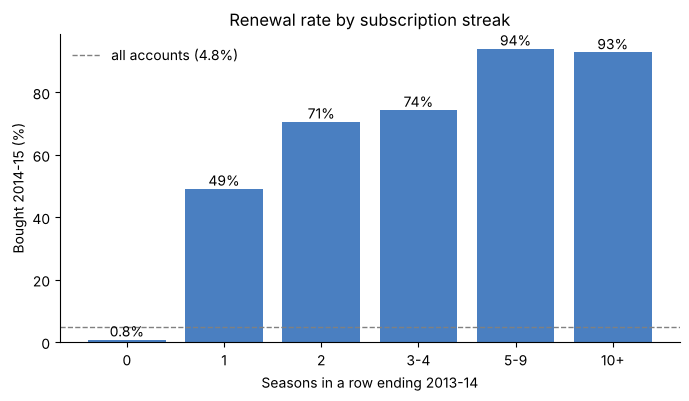

,accounts,rate
sub_streak_2013,,
0,6596,0.007580
1,55,0.490909
2,34,0.705882
3-4,39,0.743590
5-9,50,0.940000
10+,167,0.928144


In [6]:
bins = pd.cut(train_df["sub_streak_2013"], [-1, 0, 1, 2, 4, 9, 30],
              labels=["0", "1", "2", "3-4", "5-9", "10+"])
by_streak = train_df.groupby(bins, observed=False)["label"].agg(accounts="size", rate="mean")

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(by_streak.index.astype(str), by_streak["rate"] * 100, color="#4a7fc1")
ax.bar_label(bars, labels=[f"{r:.0%}" if r >= 0.01 else f"{r:.1%}" for r in by_streak["rate"]])
ax.axhline(y.mean() * 100, color="grey", linestyle="--", linewidth=1, label=f"all accounts ({y.mean():.1%})")
ax.legend(frameon=False, loc="upper left")
ax.set_xlabel("Seasons in a row ending 2013-14")
ax.set_ylabel("Bought 2014-15 (%)")
ax.set_title("Renewal rate by subscription streak")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

by_streak

## Cross-validation

Stratified 5-fold CV repeated 3 times, with the same splits for every model.

In [7]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
oof = {name: np.zeros(len(y)) for name in MODEL_NAMES}
counts = np.zeros(len(y))

for train_idx, valid_idx in cv.split(X, y):
    counts[valid_idx] += 1
    for name in MODEL_NAMES:
        model = make_model(name)
        model.fit(X.iloc[train_idx], y[train_idx])
        oof[name][valid_idx] += model.predict_proba(X.iloc[valid_idx])[:, 1]

for name in MODEL_NAMES:
    oof[name] /= counts

results = pd.Series({name: roc_auc_score(y, oof[name]) for name in MODEL_NAMES}, name="CV AUROC")
results["baseline (2013-14 seats)"] = roc_auc_score(y, X["sub_seats_2013"])
results.sort_values(ascending=False).round(4).to_frame()

,CV AUROC
xgb,0.9758
lr,0.9750
lgb,0.9750
et,0.9728
hgb,0.9718
baseline (2013-14 seats),0.9204


## Blending

Averaging ranks rather than probabilities, since AUROC only depends on order.

In [8]:
blends = [
    ("lgb", "xgb"),
    ("lgb", "xgb", "hgb"),
    ("lgb", "xgb", "et"),
    ("lgb", "xgb", "et", "lr"),
    tuple(MODEL_NAMES),
]
pd.Series({" + ".join(b): roc_auc_score(y, rank_blend([oof[m] for m in b])) for b in blends},
          name="CV AUROC").sort_values(ascending=False).round(4).to_frame()

,CV AUROC
lgb + xgb + et + lr,0.9760
lgb + xgb + hgb + et + lr,0.9758
lgb + xgb,0.9755
lgb + xgb + et,0.9753
lgb + xgb + hgb,0.9748


In [9]:
pd.DataFrame(oof).corr(method="spearman").round(2)

,lgb,xgb,hgb,et,lr
lgb,1.00,0.99,0.97,0.80,0.77
xgb,0.99,1.00,0.95,0.79,0.77
hgb,0.97,0.95,1.00,0.78,0.73
et,0.80,0.79,0.78,1.00,0.81
lr,0.77,0.77,0.73,0.81,1.00


LightGBM and XGBoost are almost identical, so logistic regression and ExtraTrees are what add variety to the blend.

## Which features matter

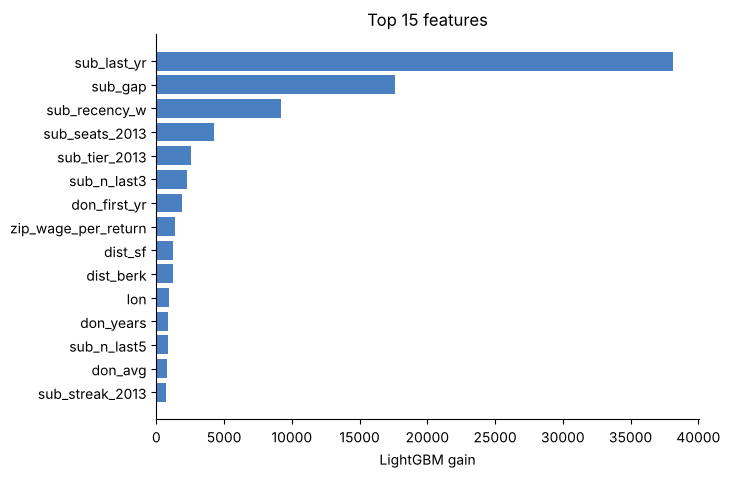

In [10]:
lgb_model = make_model("lgb").set_params(importance_type="gain").fit(X, y)
importance = pd.Series(lgb_model.feature_importances_, index=feature_cols).sort_values().tail(15)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importance.index, importance.values, color="#4a7fc1")
ax.set_xlabel("LightGBM gain")
ax.set_title("Top 15 features")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Where the model struggles

In [11]:
blend_oof = rank_blend([oof[m] for m in FINAL_BLEND])
groups = {"subscribed 2013-14": X["is_sub_2013"] == 1, "did not subscribe 2013-14": X["is_sub_2013"] == 0}
pd.DataFrame({
    name: {"accounts": mask.sum(), "bought": y[mask].sum(), "AUROC within group": roc_auc_score(y[mask], blend_oof[mask])}
    for name, mask in groups.items()
}).T.round(3)

,accounts,bought,AUROC within group
subscribed 2013-14,345.0,282.0,0.762
did not subscribe 2013-14,6596.0,50.0,0.862


Telling renewers from people who drop off, and spotting the few new buyers, is much harder than the overall score suggests.

## Final model and submission

Each blend member is trained on all the training data with 5 seeds, then the ranks are averaged.

In [12]:
predictions = []
for name in FINAL_BLEND:
    seed_preds = [make_model(name, seed).fit(X, y).predict_proba(X_test)[:, 1] for seed in range(5)]
    predictions.append(np.mean(seed_preds, axis=0))

submission = pd.DataFrame({"ID": test_df["id"], "Predicted": rank_blend(predictions)})
submission.to_csv(OUTPUT_DIR / "submission.csv", index=False)
print(f"saved {len(submission)} predictions to {OUTPUT_DIR / 'submission.csv'}")
submission.head()

saved 2975 predictions to outputs/submission.csv


,ID,Predicted
0,001i000000NuQ6Y,0.861205
1,001i000000NuQXz,0.939238
2,001i000000NuRDC,0.939599
3,001i000000NuQeg,0.841494
4,001i000000NuOQc,0.922691
